# Carterra: all 13 injections with one global Smax

Import **`carterra_rows.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it fits all 13 injections with pyKinGenie's existing one-site single-cycle fitter and one shared Smax. No data download is required.

The separate [five-injection notebook](15_carterra_csv_import.ipynb) retains the closer literature comparison. This notebook changes both the concentration selection and the capacity assumption from the published fit.

**Data origin:** [Duke TitrationAnalysis Carterra workbook](https://github.com/DukeCHSI/TitrationAnalysis/tree/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

**Timing limitation:** the 1140 s cycle period is reconstructed from nominal protocol durations. An absolute injection log was not available. The fitted kinetic constants are conditional on this assumption; the notebook is not an exact reproduction of the published analysis.

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, CarterraExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "carterra_rows.csv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: carterra_rows.csv


## File layout and single-cycle import

The CSV retains **all 13 injections** for one physical sensor (Block 1/A1/ROI 1),
worksheet rows 2–14, in their original acquisition order. The five concentrations
on page 1 of the author fit report are injections **9–13** (worksheet rows 10–14):
**62.5, 125, 250, 500, 1000 nM**. This notebook fits **every injection**, from **0.244 to 1000 nM**, with one global Smax. The published report instead fits only the five highest concentrations with local Rmax.

Use `single_cycle=True, cycle_duration=1140` to combine the row-wise exports into
one sensor with **27 steps**: baseline, association, dissociation, association,
dissociation, ... . Each following pre-association baseline extends the preceding
dissociation because analyte is absent during that interval. Responses are not
shifted or interpolated during import, and source labels are retained in
`ligand_conc_df["Source_curve"]`.

**Clock assumption:** 1140 s is the nominal sum of the source sheet's baseline
120 s, association 300 s and fitted dissociation 720 s. This is an explicit
protocol-based reconstruction, not a recovered absolute injection log. Use the
actual cycle period when available. The source excerpts retain all finite points
in each row's 0–1140 s window; their later export tails are omitted and recorded
in the manifest. No response is smoothed or replaced.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = CarterraExperiment("carterra_rows")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_csv(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id=fit_metadata["analyte"],
        concentrations=fit_metadata["cycle_concentrations"],
        concentration_unit="uM",
        single_cycle=True,
        cycle_duration=fit_metadata["cycle_duration_seconds"],
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} sensor, {len(experiment.ligand_conc_df)} injections; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 1
assert experiment.no_steps == 27
assert experiment.exp_info["single_cycle"]
assert len(experiment.ligand_conc_df) == 13

Detected layout: carterra_csv
Imported 1 sensor, 13 injections; 27 API phases.


## Available curve information

All 13 row-wise curves belong to one physical sensor in this single-cycle import.
Original row labels remain in `ligand_conc_df["Source_curve"]`. The table below
also identifies the five curves used in the separate published fit.

In [3]:
curve_ids = [f"Injection {i + 1}" for i in range(len(experiment.ligand_conc_df))]
labels = experiment.ligand_conc_df["Source_curve"].rename("Exported label")
header_info = labels.str.extract(
    r"^\[Ligand (?P<Ligand_index>\d+)-(?P<Ligand_label>\S+)\s+"
    r"(?P<Concentration_label>[^\]]+)\]\s+\[(?P<Fit_status>[^\]]+)\]$"
)
header_info.insert(0, "Injection", curve_ids)
header_info["Used in published comparison"] = experiment.ligand_conc_df["Analyte_location"].astype(int).isin(
    fit_metadata["source_concentration_entries_one_based"]
)
display(header_info)
display(labels.to_frame())

,Injection,Ligand_index,Ligand_label,Concentration_label,Fit_status,Used in published comparison
0,Injection 1,1,AE.A244,Conc. 13,NotFitted,False
1,Injection 2,1,AE.A244,Conc. 12,NotFitted,False
2,Injection 3,1,AE.A244,Conc. 11,NotFitted,False
3,Injection 4,1,AE.A244,Conc. 10,NotFitted,False
4,Injection 5,1,AE.A244,Conc. 9,NotFitted,False
5,Injection 6,1,AE.A244,Conc. 8,NotFitted,False
6,Injection 7,1,AE.A244,Conc. 7,NotFitted,False
7,Injection 8,1,AE.A244,Conc. 6,NotFitted,False
8,Injection 9,1,AE.A244,Conc. 5,NotFitted,True
9,Injection 10,1,AE.A244,Conc. 4,NotFitted,True


,Exported label
0,[Ligand 1-AE.A244 Conc. 13] [NotFitted]
1,[Ligand 1-AE.A244 Conc. 12] [NotFitted]
2,[Ligand 1-AE.A244 Conc. 11] [NotFitted]
3,[Ligand 1-AE.A244 Conc. 10] [NotFitted]
4,[Ligand 1-AE.A244 Conc. 9] [NotFitted]
5,[Ligand 1-AE.A244 Conc. 8] [NotFitted]
6,[Ligand 1-AE.A244 Conc. 7] [NotFitted]
7,[Ligand 1-AE.A244 Conc. 6] [NotFitted]
8,[Ligand 1-AE.A244 Conc. 5] [NotFitted]
9,[Ligand 1-AE.A244 Conc. 4] [NotFitted]


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Injection", curve_ids)
display(concentration_info[["Injection", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].notna().all()

,Injection,Concentration_micromolar,SampleID
0,Injection 1,0.000244,AE.A244
1,Injection 2,0.000488,AE.A244
2,Injection 3,0.000977,AE.A244
3,Injection 4,0.001950,AE.A244
4,Injection 5,0.003910,AE.A244
5,Injection 6,0.007810,AE.A244
6,Injection 7,0.015600,AE.A244
7,Injection 8,0.031300,AE.A244
8,Injection 9,0.062500,AE.A244
9,Injection 10,0.125000,AE.A244


## Plate information, when available

The ligand and concentration indices are not verified chip spots or plate wells. The retained rows contain no row/column mapping, so no plate layout can be drawn.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported single-cycle sensorgram

Plot every retained observation on the reconstructed common clock, before
alignment. The signal already bound remains visible as concentration increases.
Vertical lines mark associations; no independent zeroing is applied to later
injections.

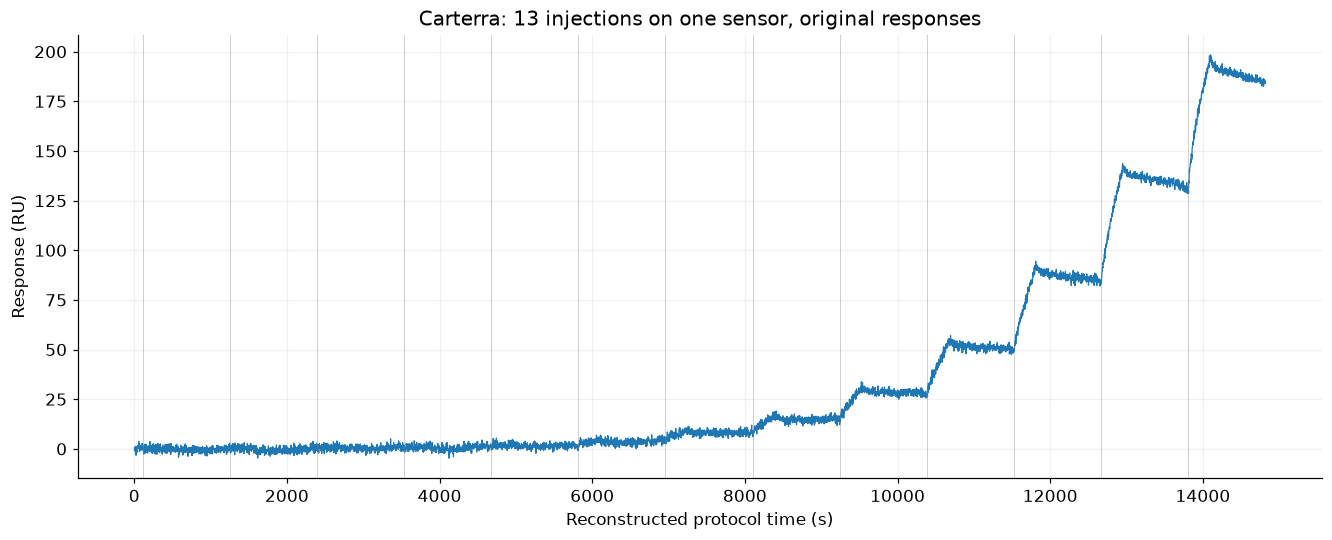

In [6]:
time = np.concatenate(experiment.xs[0])
response = np.concatenate(experiment.ys[0])
fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
ax.plot(time, response, linewidth=0.8)
for start in experiment.df_steps.loc[experiment.df_steps["Type"] == "ASSOC", "Start"]:
    ax.axvline(start, color="grey", linewidth=0.6, alpha=0.4)
ax.set(xlabel="Reconstructed protocol time (s)", ylabel="Response (RU)",
       title="Carterra: 13 injections on one sensor, original responses")
ax.grid(alpha=0.18)
plt.show()

## Check the imported sequence

There is one sensor and 13 association/dissociation pairs. Each injection has its
own concentration/location in `ligand_conc_df`. Later baseline observations
belong to the preceding dissociation; they are not new empty-surface baselines.

In [7]:
display(experiment.df_steps[["Name", "Type", "Start"]])
print("Retained observations:", sum(len(step) for step in experiment.xs[0]))
assert np.all(np.diff(np.concatenate(experiment.xs[0])) > 0)

,Name,Type,Start
0,Baseline,BASELINE,1.25
1,Association 1,ASSOC,120.00
2,Dissociation 1,DISASSOC,420.00
3,Association 2,ASSOC,1260.00
4,Dissociation 2,DISASSOC,1560.00
5,Association 3,ASSOC,2400.00
6,Dissociation 3,DISASSOC,2700.00
7,Association 4,ASSOC,3540.00
8,Dissociation 4,DISASSOC,3840.00
9,Association 5,ASSOC,4680.00


Retained observations: 6717


The fitting copy below retains the complete sequence and selects **all 13 injections** for parameter estimation.

## One-site single-cycle model with global Smax

Use pyKinGenie's existing one-site association/dissociation fitter with
`shared_smax=True`: **one Kd, one koff and one Smax shared by all 13 injections**.
The source sample sheet specifies association 120–420 s, dissociation 420–1140 s,
no regeneration and no bulk shift.

`align_association` aligns only the first baseline because all subsequent
associations directly follow dissociations. The existing fitter starts the first
association at zero aligned response and carries the fitted bound signal forward
from each dissociation into the following association. No custom fitter or
per-injection reset is used.

The [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv)
uses five injections and local Rmax. Its values are included below as context,
**not as an identical fitting setup**. Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/).

## Align once and use pyKinGenie's single-cycle fitter

Call the existing `align_association(inplace=True, npoints=10)` on a copy of
the full imported sequence. All later associations follow `DISASSOC`, so the
method leaves their relative starting responses intact.

Generate the fit using **all 13 injections** with `trim_time=0`.
The preceding baseline before each subsequent association remains part of the
zero-analyte dissociation and is fitted as such. Thus the continuous fit includes
these inter-injection wash observations in addition to the author's nominal
per-row dissociation window. The global clock is reconstructed from the explicit
cycle period above; no original absolute timing log was available.

The existing fitter, not notebook code, handles the initial signal and bound-state
carry-over. No alternative models or optimizers are introduced.

In [8]:
from copy import deepcopy
from pykingenie.utils.processing import detect_time_list_continuos

fit_experiment = deepcopy(experiment)
fit_experiment.align_association(inplace=True, npoints=10)

fit_analyzer = KineticsAnalyzer()
fit_analyzer.add_experiment(fit_experiment, fit_experiment.name)
fit_analyzer.merge_ligand_conc_df()
selected = fit_analyzer.combined_ligand_conc_df.copy()
selected["Select"] = True
assert selected["Select"].sum() == 13
np.testing.assert_allclose(
    selected.loc[selected["Select"], "[Analyte] (μM)"], fit_metadata["cycle_concentrations"]
)
messages = fit_analyzer.generate_fittings(selected, trim_time=0)
print("\n".join(messages))
fit_analyzer.submit_steady_state_fitting()

Creating a new fitting object for sample: AE.A244


In [9]:
fitter = next(iter(fit_analyzer.fittings.values()))
assert fitter.is_single_cycle
continuity = detect_time_list_continuos(fitter.time_assoc_lst, fitter.time_disso_lst)
assert all(continuity)
assert len(fitter.assoc_lst) == 13
assert len(np.unique(fitter.smax_id)) == 1
print("Single-cycle fitter:", fitter.is_single_cycle)
print("Carry state from previous dissociation:", continuity)
fitter.fit_one_site_assoc_and_disso(shared_smax=True, calc_loo=True)
assert len(fitter.Smax) == 1
assert len(fitter.params) == 3
display(fitter.fit_params_kinetics)
print("Fitted injections:", len(fitter.assoc_lst))
print("Fitted parameters:", len(fitter.params))

Single-cycle fitter: True
Carry state from previous dissociation: [np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_]


,Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s]
0,0.022363,0.000086,224.183513,0.003837


Fitted injections: 13
Fitted parameters: 3


## Leave-one-injection-out parameter errors

`calc_loo=True` runs pyKinGenie's existing leave-one-out implementation:
each refit omits one injection's association and dissociation observations,
then fits the remaining 12 injections with one shared Smax. All 13 omissions
must succeed before the table assigns injection identities to the results.

The native method stores Kd and koff for each refit and their mean and standard
deviation. The table below converts units and derives kon = koff/Kd for each
refit; it does not introduce a new fitting implementation. The displayed SD uses
the library's convention (`ddof=0`). This is the spread of deletion estimates,
not a jackknife standard error or a confidence interval. The native leave-one-out
method does not retain a distribution of Smax estimates.

**Single-cycle interpretation:** deleting an injection introduces a gap in the
sequence. The existing fitter estimates the initial response of the next retained
association from its observed signal, then resumes state propagation. These
results measure parameter sensitivity to omitting an injection; they are not
held-out prediction errors or a simulation of physically skipping an injection.

If injection 1 is omitted, injection 2 keeps its original time and its initial response is automatically estimated from its first 30 s, with the first measured response used if estimation fails. This starting value is held fixed during the kinetic refit, rather than being an additional optimized parameter. It is not forced to zero.

In [10]:
assert len(fitter.Kd_loo) == len(fitter.k_off_loo) == 13
assert np.isfinite(fitter.Kd_loo).all() and np.isfinite(fitter.k_off_loo).all()

print("Successful leave-one-injection-out refits:", len(fitter.Kd_loo), "/ 13")
print("Native pyKinGenie leave-one-out summary:")
display(fitter.df_fit_loo)

loo_fits = pd.DataFrame({
    "Omitted injection": np.arange(1, 14),
    "Omitted concentration (nM)": np.asarray(fitter.lig_conc_lst) * 1e3,
    "Kd (nM)": np.asarray(fitter.Kd_loo) * 1e3,
    "koff (s⁻¹)": np.asarray(fitter.k_off_loo),
})
loo_fits["kon (M⁻¹s⁻¹)"] = np.asarray(fitter.k_off_loo) / np.asarray(fitter.Kd_loo) * 1e6
columns = ["Kd (nM)", "koff (s⁻¹)", "kon (M⁻¹s⁻¹)"]
loo_summary = pd.DataFrame({
    "Parameter": columns,
    "Full fit": [fitter.Kd * 1e3, fitter.k_off, fitter.k_off / fitter.Kd * 1e6],
    "LOO mean": loo_fits[columns].mean().to_numpy(),
    "LOO SD": loo_fits[columns].std(ddof=0).to_numpy(),
    "LOO minimum": loo_fits[columns].min().to_numpy(),
    "LOO maximum": loo_fits[columns].max().to_numpy(),
})
loo_summary["Relative LOO SD (%)"] = 100 * loo_summary["LOO SD"] / loo_summary["LOO mean"]
display(loo_summary)
display(loo_fits)


Successful leave-one-injection-out refits: 13 / 13
Native pyKinGenie leave-one-out summary:


,Kd [µM],k_off [1/s]
0,2.36e-02 ± 2.62e-03,9.32e-05 ± 1.01e-05


,Parameter,Full fit,LOO mean,LOO SD,LOO minimum,LOO maximum,Relative LOO SD (%)
0,Kd (nM),22.363401,23.591045,2.620063,17.988677,26.728170,11.106176
1,koff (s⁻¹),0.000086,0.000093,0.000010,0.000070,0.000107,10.802663
2,kon (M⁻¹s⁻¹),3836.928596,3957.016569,176.256245,3718.761634,4465.378237,4.454271


,Omitted injection,Omitted concentration (nM),Kd (nM),koff (s⁻¹),kon (M⁻¹s⁻¹)
0,1,0.244,26.728170,0.000107,4006.852774
1,2,0.488,26.142670,0.000105,4002.543749
2,3,0.977,25.946913,0.000104,4013.127928
3,4,1.950,25.072085,0.000100,3996.046897
4,5,3.910,23.971959,0.000095,3951.234061
5,6,7.810,24.537899,0.000098,4000.317741
6,7,15.600,23.895469,0.000094,3927.117217
7,8,31.300,24.236328,0.000094,3895.252211
8,9,62.500,24.013150,0.000089,3718.761634
9,10,125.000,22.340981,0.000083,3724.921079


## All 13 injections: single-cycle fit with global Smax

The package's `plot_association_dissociation` displays observations and the
fitted curves returned by `KineticsFitter`. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Sensorgram_Example.pdf).
Locate Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. Only injections 9–13 appear on **page 1** of that report; its local-Rmax fit differs from the all-injection global-Smax fit below.

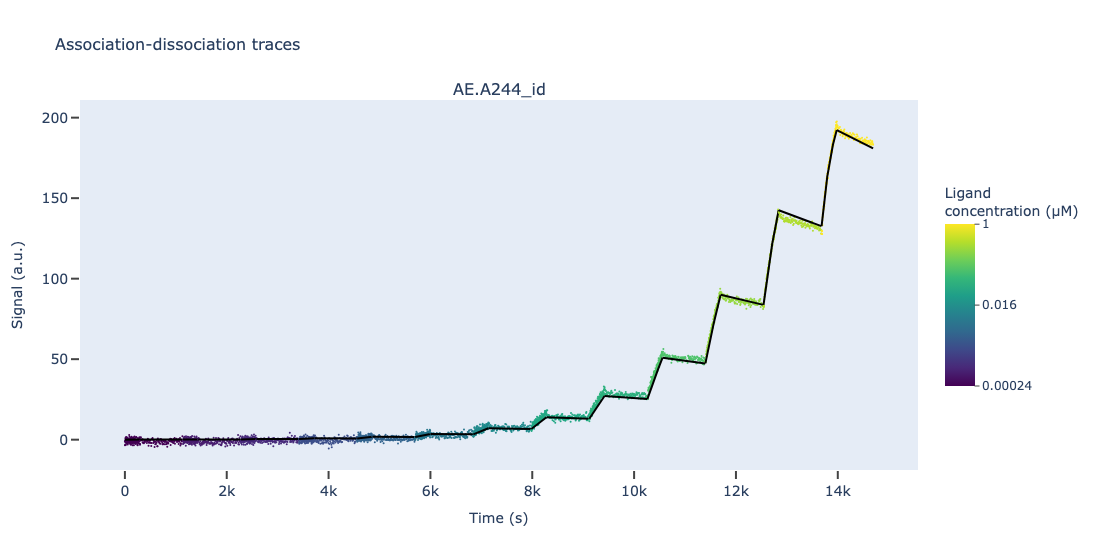

In [11]:
from pykingenie import plot_association_dissociation
from IPython.display import Image

fig_fit = plot_association_dissociation(
    fit_analyzer, split_by_smax_id=False,
    plot_width=22, plot_height=11, marker_size=2, line_width=2,
)
display(Image(data=fig_fit.to_image(format="png", width=1100, height=550)))

## Published values as context: different selection and Smax assumption

The table uses `fitter.Kd` and `fitter.k_off` directly. kon is their ratio.
Only unit conversion and percentage differences are calculated below.
The single global Smax is shown in the library result table above. The published values use five injections and local Rmax, whereas this notebook uses all 13 and global Smax.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20Carterra/Titration%20Analysis_Carterra_Report_Example.csv).
Use Block 1 / A1 / ROI 1, fitting #1; ligand CH31 10 µg/ml, analyte AE.A244. These are the values in the Published column below.

In [12]:
reference = fit_metadata["literature_reference"]["parameters_molar"]
comparison = pd.DataFrame({
    "Parameter": ["kon", "koff", "Kd"],
    "Unit": ["M⁻¹ s⁻¹", "s⁻¹", "nM"],
    "Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
    "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3],
})
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
display(comparison.style.format({
    "Published": "{:.5g}", "pyKinGenie": "{:.5g}", "Difference (%)": "{:+.2f}",
}))

,Parameter,Unit,Published,pyKinGenie,Difference (%)
0,kon,M⁻¹ s⁻¹,5161.2,3836.9,-25.66
1,koff,s⁻¹,7.3734e-05,8.5807e-05,+16.37
2,Kd,nM,14.286,22.363,+56.54


## Interpretation and limitations

The executed global-Smax fit gives approximately **Kd = 22.36 nM**,
**koff = 8.581 × 10⁻⁵ s⁻¹**, **kon = 3837 M⁻¹s⁻¹** and **Smax = 224.18 RU**.
Only three parameters are fitted. Leave-one-injection-out sensitivity is reported above.

One shared capacity leaves systematic response deviations in several injections.
The early injections have weak signals close to the noise. Treat these kinetic
constants as conditional on the one-site/global-capacity model and baseline and
timing assumptions; convergence alone does not establish their accuracy.

The nominal cycle period of 1140 s reconstructs the protocol clock; no absolute
injection log was available. Following baseline washes extend each preceding
dissociation. The published fit uses only the five highest concentrations and
local Rmax, so this is not an exact reproduction of its parameters.

See the [five-injection literature comparison](15_carterra_csv_import.ipynb),
[SPR_FITTING.md](SPR_FITTING.md), and [source notes](data/spr_exports/SOURCES.md).